# Cross-Model Comparison

All models side by side, with paired tests between models.

In [1]:
import os
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

# ── Paths ─────────────────────────────────────────────────────────────────
NOTEBOOK_DIR = Path(os.path.abspath("")).resolve()
MOD = NOTEBOOK_DIR.parent / "modeling"
M1, M2, M3 = MOD / "01_csp_lda" / "results", MOD / "02_riemannian" / "results", MOD / "03_eegnet" / "results"
SIG = pd.read_csv(NOTEBOOK_DIR / "cross_subject_persubject_significance.csv")   # from cross_subject_permtest.py

TASKS   = {"T1": "task1_LR", "T2": "task2_FF"}
MODELS  = ["M1 CSP+LDA", "M2A Riemann", "M2B Riemann+align", "M3 EEGNet"]
METRICS = {"acc": "Acc", "bal_acc": "Bal.Acc", "auc": "AUC", "kappa": "Kappa",
           "sensitivity": "Sensitivity", "specificity": "Specificity"}


def bh(df):
    return pd.Series(multipletests(df["perm_pvalue"].fillna(1.0), method="fdr_bh")[0].astype(int),
                     index=df["subject"])


def cross_fdr(variant, task):
    return SIG[(SIG.variant == variant) & (SIG.task == task)].set_index("subject")["fdr_sig"].astype(int)


# ── Collect per-subject accuracy + summary row for every model x scenario x task ──
subj, rows = {}, []

def add(model, scenario, task, df, pre, acc_col, fdr, pooled=None):
    acc = df.set_index("subject")[acc_col]
    subj[(model, scenario, task)] = acc
    if pooled is not None:                       # Cross: pooled (fold-mean) metrics + pooled permutation p
        m = {k: pooled[k] for k in METRICS}
        group_p = pooled["perm_pvalue"]
    else:                                        # Within/Transfer: mean over subjects + Wilcoxon vs 0.5
        m = {"acc": acc.mean(), **{k: df[f"{pre}{k}"].mean() for k in list(METRICS)[1:]}}
        group_p = wilcoxon(acc - 0.5).pvalue
    rows.append({"Scenario": scenario, "Task": task, "Model": model,
                 **{METRICS[k]: round(float(v), 3) for k, v in m.items()},
                 "Group p": f"{group_p:.2g}", "FDR sig": f"{int(fdr.sum())}/106"})


for T, key in TASKS.items():
    # M1 CSP+LDA
    w = pd.read_csv(M1 / f"model1_{key}_within_subject.csv")
    add("M1 CSP+LDA", "Within", T, w, "", "acc_loro", bh(w))
    c  = pd.read_csv(M1 / f"model1_{key}_cross_subject.csv")
    cp = pd.read_csv(M1 / f"model1_{key}_cross_subject_pooled.csv").iloc[0]
    add("M1 CSP+LDA", "Cross", T, c, "", "acc", cross_fdr("M1-LDA", T), cp)
    t = pd.read_csv(M1 / f"model1_transfer_{key}.csv")
    add("M1 CSP+LDA", "Transfer", T, t, "", "transfer_acc", bh(t))

    # M2 Riemann (2A unaligned, 2B aligned)
    w = pd.read_csv(M2 / f"model2_{key}_within_subject.csv")
    add("M2A Riemann", "Within", T, w, "", "acc", w.set_index("subject")["perm_pvalue_fdr_sig"])
    c  = pd.read_csv(M2 / f"model2_{key}_cross_subject.csv")
    cp = pd.read_csv(M2 / f"model2_{key}_cross_subject_pooled.csv").set_index("variant")
    t  = pd.read_csv(M2 / f"model2_transfer_{key}.csv")
    for model, pre, variant in [("M2A Riemann", "m2a_", "M2A-Riemann"), ("M2B Riemann+align", "m2b_", "M2B-Riemann-aligned")]:
        add(model, "Cross", T, c, pre, f"{pre}acc", cross_fdr(variant, T), cp.loc[pre[:-1]])
        add(model, "Transfer", T, t, pre, f"{pre}acc", t.set_index("subject")[f"{pre}perm_fdr_sig"])

    # M3 EEGNet
    w = pd.read_csv(M3 / f"model3_eegnet_within_{key}.csv")
    add("M3 EEGNet", "Within", T, w, "eegnet_", "eegnet_acc", w.set_index("subject")["eegnet_perm_pvalue_fdr_sig"])
    c  = pd.read_csv(M3 / f"model3_eegnet_cross_{key}.csv")
    cp = pd.read_csv(M3 / f"model3_eegnet_cross_{key}_pooled.csv").iloc[0]
    add("M3 EEGNet", "Cross", T, c, "eegnet_", "eegnet_acc", cross_fdr("M3-EEGNet", T), cp)
    t = pd.read_csv(M3 / f"model3_eegnet_transfer_{key}.csv")
    add("M3 EEGNet", "Transfer", T, t, "eegnet_", "eegnet_acc", t.set_index("subject")["eegnet_perm_fdr_sig"])

# ── Summary table ──────────────────────────────────────────────────────────
summary = pd.DataFrame(rows)
summary["_s"] = summary["Scenario"].map({"Within": 0, "Cross": 1, "Transfer": 2})
summary["_m"] = summary["Model"].map({m: i for i, m in enumerate(MODELS)})
summary = summary.sort_values(["_s", "Task", "_m"]).drop(columns=["_s", "_m"]).set_index(["Scenario", "Task", "Model"])

print("=" * 90)
print("All models — Summary Statistics")
print("(Within/Transfer: mean across 106 subjects · Cross: mean across 5 GroupKFold folds)")
print("(Group p: Wilcoxon vs 0.5 for Within/Transfer · pooled permutation test for Cross)")
print("=" * 90)
display(summary)


All models — Summary Statistics
(Within/Transfer: mean across 106 subjects · Cross: mean across 5 GroupKFold folds)
(Group p: Wilcoxon vs 0.5 for Within/Transfer · pooled permutation test for Cross)


Acc  Bal.Acc  ...  Group p  FDR sig
Scenario Task Model                              ...                  
Within   T1   M1 CSP+LDA         0.583    0.583  ...  1.7e-11   22/106
              M2A Riemann        0.598    0.596  ...  6.5e-12   22/106
              M3 EEGNet          0.509    0.504  ...     0.18    0/106
         T2   M1 CSP+LDA         0.643    0.644  ...  1.1e-14   39/106
              M2A Riemann        0.645    0.644  ...    1e-14   47/106
              M3 EEGNet          0.539    0.532  ...  2.2e-06   16/106
Cross    T1   M1 CSP+LDA         0.611    0.611  ...    0.001   30/106
              M2A Riemann        0.577    0.577  ...    0.001    5/106
              M2B Riemann+align  0.618    0.618  ...    0.001   29/106
              M3 EEGNet          0.640    0.639  ...    0.001   39/106
         T2   M1 CSP+LDA         0.614    0.614  ...    0.001   32/106
              M2A Riemann        0.594    0.594  ...    0.001   18/106
              M2B Riemann+align  0.641    0.641  ...    0.001   35/106
              M3 EEGNet          0.629    0.630  ...    0.001   39/106
Transfer T1   M1 CSP+LDA         0.572    0.574  ...  1.7e-08   15/106
              M2A Riemann        0.590    0.590  ...  6.6e-12   19/106
              M2B Riemann+align  0.602    0.602  ...    4e-11   25/106
              M3 EEGNet          0.514    0.512  ...    0.027    0/106
         T2   M1 CSP+LDA         0.624    0.624  ...  6.6e-14   38/106
              M2A Riemann        0.628    0.627  ...  3.7e-15   39/106
              M2B Riemann+align  0.663    0.664  ...    4e-17   44/106
              M3 EEGNet          0.549    0.549  ...  0.00012   13/106

[22 rows x 8 columns]

In [2]:
# ── Paired tests between models (per subject) ─────────────────────────────
tests = []
for scenario in ["Within", "Cross", "Transfer"]:
    for T in TASKS:
        available = [m for m in MODELS if (m, scenario, T) in subj]
        for a, b in combinations(available, 2):
            pair = pd.concat([subj[(a, scenario, T)], subj[(b, scenario, T)]], axis=1, join="inner").dropna()
            diff = pair.iloc[:, 0] - pair.iloc[:, 1]
            tests.append({"Scenario": scenario, "Task": T, "Model A": a, "Model B": b, "n": len(pair),
                          "Mean diff (A−B)": round(diff.mean(), 3),
                          "p": wilcoxon(pair.iloc[:, 0], pair.iloc[:, 1]).pvalue})

tests = pd.DataFrame(tests)
tests["p (FDR)"] = multipletests(tests["p"], method="fdr_bh")[1]
tests["Result"] = np.where(tests["p (FDR)"] < 0.05,
                           np.where(tests["Mean diff (A−B)"] > 0, "A > B", "B > A"), "n.s.")
tests["p"] = tests["p"].map(lambda x: f"{x:.2g}")
tests["p (FDR)"] = tests["p (FDR)"].map(lambda x: f"{x:.2g}")

print("Paired Wilcoxon on per-subject accuracy (n = 106 subjects); BH-FDR across all comparisons")
display(tests.set_index(["Scenario", "Task"]))


Paired Wilcoxon on per-subject accuracy (n = 106 subjects); BH-FDR across all comparisons


Model A            Model B  ...  p (FDR)  Result
Scenario Task                                        ...                 
Within   T1           M1 CSP+LDA        M2A Riemann  ...     0.12    n.s.
         T1           M1 CSP+LDA          M3 EEGNet  ...    3e-09   A > B
         T1          M2A Riemann          M3 EEGNet  ...  2.2e-09   A > B
         T2           M1 CSP+LDA        M2A Riemann  ...     0.53    n.s.
         T2           M1 CSP+LDA          M3 EEGNet  ...  9.6e-11   A > B
         T2          M2A Riemann          M3 EEGNet  ...  9.6e-11   A > B
Cross    T1           M1 CSP+LDA        M2A Riemann  ...   0.0064   A > B
         T1           M1 CSP+LDA  M2B Riemann+align  ...     0.35    n.s.
         T1           M1 CSP+LDA          M3 EEGNet  ...   0.0086   B > A
         T1          M2A Riemann  M2B Riemann+align  ...  3.6e-06   B > A
         T1          M2A Riemann          M3 EEGNet  ...  2.5e-06   B > A
         T1    M2B Riemann+align          M3 EEGNet  ...    0.051    n.s.
         T2           M1 CSP+LDA        M2A Riemann  ...      0.2    n.s.
         T2           M1 CSP+LDA  M2B Riemann+align  ...    0.031   B > A
         T2           M1 CSP+LDA          M3 EEGNet  ...     0.22    n.s.
         T2          M2A Riemann  M2B Riemann+align  ...  3.7e-07   B > A
         T2          M2A Riemann          M3 EEGNet  ...   0.0063   B > A
         T2    M2B Riemann+align          M3 EEGNet  ...      0.2    n.s.
Transfer T1           M1 CSP+LDA        M2A Riemann  ...    0.082    n.s.
         T1           M1 CSP+LDA  M2B Riemann+align  ...   0.0064   B > A
         T1           M1 CSP+LDA          M3 EEGNet  ...  1.8e-05   A > B
         T1          M2A Riemann  M2B Riemann+align  ...    0.088    n.s.
         T1          M2A Riemann          M3 EEGNet  ...  6.6e-09   A > B
         T1    M2B Riemann+align          M3 EEGNet  ...  2.3e-09   A > B
         T2           M1 CSP+LDA        M2A Riemann  ...     0.66    n.s.
         T2           M1 CSP+LDA  M2B Riemann+align  ...   0.0014   B > A
         T2           M1 CSP+LDA          M3 EEGNet  ...  2.2e-08   A > B
         T2          M2A Riemann  M2B Riemann+align  ...  7.6e-06   B > A
         T2          M2A Riemann          M3 EEGNet  ...  2.2e-08   A > B
         T2    M2B Riemann+align          M3 EEGNet  ...  4.9e-12   A > B

[30 rows x 7 columns]

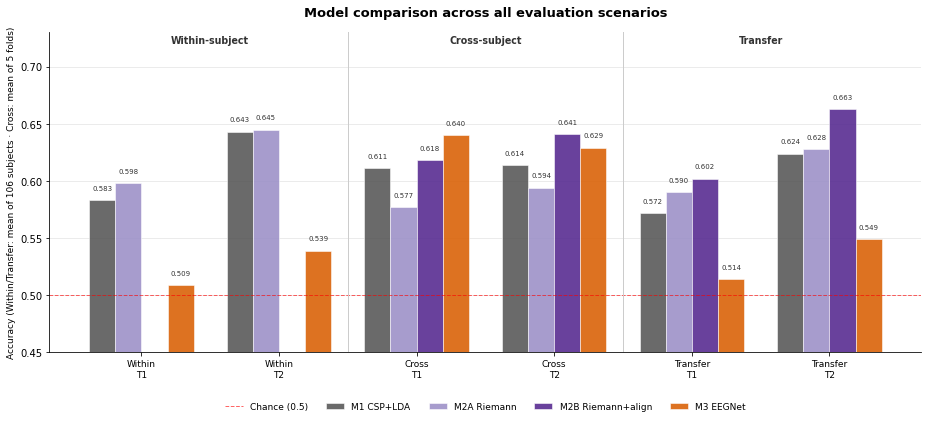

In [3]:
# ── Accuracy of all models, every scenario x task ─────────────────────────
import matplotlib.pyplot as plt

FIGURES = NOTEBOOK_DIR / "figures"
FIGURES.mkdir(exist_ok=True)
COLORS = {"M1 CSP+LDA": "#555555", "M2A Riemann": "#9b8fc7", "M2B Riemann+align": "#54278f", "M3 EEGNet": "#d95f02"}
GROUPS = [(s, t) for s in ["Within", "Cross", "Transfer"] for t in TASKS]
acc = summary["Acc"]

fig, ax = plt.subplots(figsize=(13, 6))
x, width = np.arange(len(GROUPS)), 0.19
for i, model in enumerate(MODELS):
    offset = (i - (len(MODELS) - 1) / 2) * width
    pts = [(x[g] + offset, acc[(s, t, model)]) for g, (s, t) in enumerate(GROUPS) if (s, t, model) in acc.index]
    ps, hs = zip(*pts)
    ax.bar(ps, hs, width=width, color=COLORS[model], alpha=0.88, label=model, edgecolor="white", linewidth=0.6)
    for p, h in pts:
        ax.text(p, h + 0.008, f"{h:.3f}", ha="center", va="bottom", fontsize=7, color="#333")

ax.axhline(0.5, color="red", linestyle="--", linewidth=1, alpha=0.6, label="Chance (0.5)")
for sep in [1.5, 3.5]:
    ax.axvline(sep, color="#ccc", linewidth=1)
for xp, lbl in [(0.5, "Within-subject"), (2.5, "Cross-subject"), (4.5, "Transfer")]:
    ax.text(xp, 0.965, lbl, ha="center", transform=ax.get_xaxis_transform(), fontsize=9.5, fontweight="bold", color="#333")
ax.set_xticks(x)
ax.set_xticklabels([f"{s}\n{t}" for s, t in GROUPS], fontsize=9)
ax.set_ylabel("Accuracy (Within/Transfer: mean of 106 subjects · Cross: mean of 5 folds)", fontsize=9)
ax.set_ylim(0.45, 0.73)
ax.set_title("Model comparison across all evaluation scenarios", fontsize=13, fontweight="bold", pad=16)
ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=5, frameon=False)
ax.yaxis.grid(True, alpha=0.3); ax.set_axisbelow(True)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES / "cross_model_comparison_bar.png", dpi=150, bbox_inches="tight")
plt.show()
